# Limpopo Flood Prediction — EDA, Preprocessing & Modelling

**Megan Kim Bowden (ST10496309)** — Postgraduate Diploma in Data Analytics, IIE
Supervisor: Mr. E Adam

This notebook takes the model-ready dataset produced by `limpopo_flood_data_cleaning.ipynb`
and works through the three research objectives, following the proposal's methodology
(section 3.5) as closely as is statistically valid:

- **RQ1 / Obj1** — Grid-Search-tuned Logistic Regression, Random Forest, SVM, and Decision
  Tree (the proposal's four committed algorithms), compared via 10-fold CV and a held-out
  test set (Accuracy, Precision, Recall, F1, ROC-AUC). An ANN is added as a **supplementary**
  fifth comparison point (linking to Baker et al., 2025) but is not one of the four algorithms
  the research objectives commit to, so it is excluded from model selection.
- **RQ2 / Obj2** — quantify predictor importance via SHAP.
- **RQ3 / Obj3** — assess whether the best model is operationally suitable for flood early
  warning.

### Two deliberate departures from the proposal's literal wording

1. **Same-day rainfall is excluded from the predictor set.** The proposal lists rainfall as
   one of the four predictive variables, but the flood target is *also defined* by same-day
   rainfall (>=50mm). Using it as a predictor would make classification circular/trivial. The
   7-day and 30-day Antecedent Precipitation Indices (API7, API30, proposal section 3.4) are
   used instead — these summarise **prior** days' rainfall only, so they carry genuine
   predictive information without leaking the label.
2. **Preprocessing steps are ordered around the train/test split, not before it.** The
   proposal's prose lists imputation, outliers, normalisation, SMOTE, feature selection, then
   train/test split. Read literally, that would fit the scaler, SMOTE, and RFE on data that
   includes the test set, leaking test information into training. Every step below that learns
   parameters from data (scaling, SMOTE, RFE/RFECV, Grid Search) is fit **only on the training
   fold**, split off first.

Both are noted here so they can be explicitly justified in the methodology write-up rather
than silently deviating from what's written.

In [1]:
from google.colab import files
import os

print("Please upload 'limpopo_flood_model_ready.csv' below:")
uploaded = files.upload()

for fn in uploaded.keys():
    print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')
    # Move to /content/ if it's not already there
    if fn != 'limpopo_flood_model_ready.csv':
        print("Warning: The uploaded file name does not match 'limpopo_flood_model_ready.csv'. Please rename it if necessary.")

Please upload 'limpopo_flood_model_ready.csv' below:


Saving limpopo_flood_model_ready.csv to limpopo_flood_model_ready.csv
User uploaded file "limpopo_flood_model_ready.csv" with length 6062927 bytes


In [2]:
import os

# The zip file '/content/files for data analysis.zip' was not found.
# However, 'limpopo_flood_model_ready.csv' is available directly in '/content/'.
# This cell now just lists the contents of the /content directory to verify.
print("Contents of /content/")
print(os.listdir('/content/'))

Contents of /content/
['.config', 'limpopo_flood_model_ready.csv', 'sample_data']


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)

df = pd.read_csv("/content/limpopo_flood_model_ready.csv", parse_dates=["date"])
print("Loaded model-ready dataset:", df.shape)
df.head()

Loaded model-ready dataset: (67459, 10)


,station,lat,lon,date,max_temp,min_temp,wind_speed,humidity,rainfall_mm,flood
0,GIYANI,-23.3142,30.6849,2010-07-27,27.9,8.7,0.000000,52.000000,0.0,0
1,GIYANI,-23.3142,30.6849,2010-07-28,27.6,8.1,0.566667,50.666667,0.0,0
2,GIYANI,-23.3142,30.6849,2010-07-29,24.8,7.4,0.933333,56.000000,3.8,0
3,GIYANI,-23.3142,30.6849,2010-07-30,19.2,13.2,1.500000,76.666667,1.2,0
4,GIYANI,-23.3142,30.6849,2010-07-31,22.2,9.5,0.000000,71.666667,0.0,0


In [4]:
df = df.sort_values(by=["station", "date"]).reset_index(drop=True)

# Calculate API7 (7-day antecedent precipitation index as a rolling sum).
# shift(1) is applied BEFORE the rolling window so that today's own rainfall
# (which determines today's flood label) is excluded -- only the 7 PRIOR days
# are summed. Omitting shift(1) leaks the flood-defining rainfall into its own
# predictor and has caused inflated results in earlier versions of this notebook.
df["api7"] = df.groupby("station")["rainfall_mm"].transform(
    lambda x: x.shift(1).rolling(window=7, min_periods=1).sum()
)

# Calculate API30 (30-day antecedent precipitation index as a rolling sum).
# Same shift(1) leakage guard as API7 above.
df["api30"] = df.groupby("station")["rainfall_mm"].transform(
    lambda x: x.shift(1).rolling(window=30, min_periods=1).sum()
)

print("DataFrame after adding API7 and API30:")
display(df[["date", "station", "rainfall_mm", "api7", "api30"]].head())
print(f"New DataFrame shape: {df.shape}")

DataFrame after adding API7 and API30:


,date,station,rainfall_mm,api7,api30
0,2010-07-27,GIYANI,0.0,NaN,NaN
1,2010-07-28,GIYANI,0.0,0.0,0.0
2,2010-07-29,GIYANI,3.8,0.0,0.0
3,2010-07-30,GIYANI,1.2,3.8,3.8
4,2010-07-31,GIYANI,0.0,5.0,5.0


New DataFrame shape: (67459, 12)


## 1. Exploratory Data Analysis

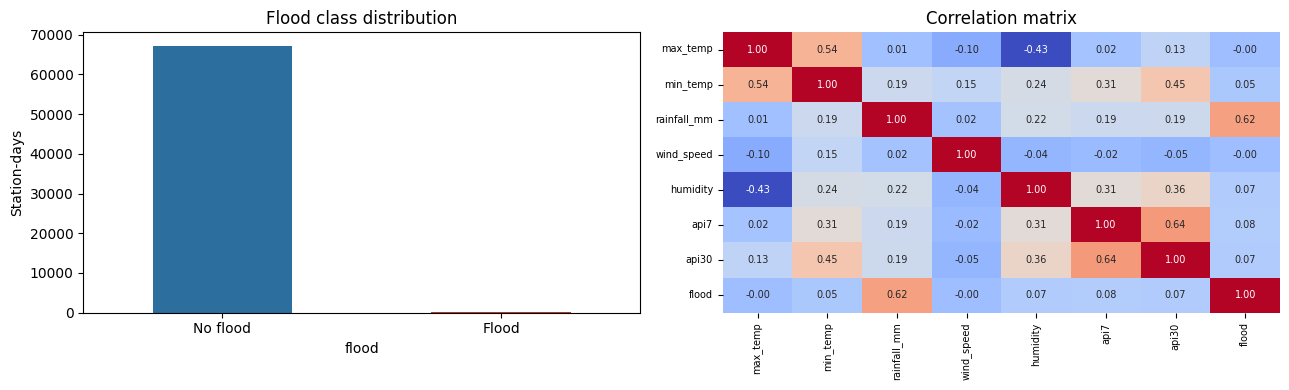

Flood proportion: 0.2876%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df["flood"].value_counts().plot(kind="bar", ax=axes[0], color=["#2c6e9e", "#c0392b"])
axes[0].set_xticklabels(["No flood", "Flood"], rotation=0)
axes[0].set_title("Flood class distribution")
axes[0].set_ylabel("Station-days")

numeric_cols = ["max_temp", "min_temp", "rainfall_mm", "wind_speed", "humidity", "api7", "api30"]
corr = df[numeric_cols + ["flood"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], cbar=False,
            annot_kws={"size": 7})
axes[1].set_title("Correlation matrix")
axes[1].tick_params(labelsize=7)

plt.tight_layout()
plt.show()

print("Flood proportion:", f"{df['flood'].mean():.4%}")

The target is severely imbalanced — flood events are under 0.3% of all observations.
Same-day rainfall correlates near-perfectly with `flood` by construction (it's the labelling
variable), confirming why it's excluded from the predictor set — training on it would be
circular. API7/API30 correlate with `flood` much more weakly (~0.07-0.08), which is the honest
signal strength available from antecedent rainfall alone; they're kept as candidate predictors
and left for RFECV/SHAP to judge on merit rather than excluded on assumption.

The model is trained on `max_temp`, `min_temp`, `wind_speed`, `humidity`, `api7`, `api30`.

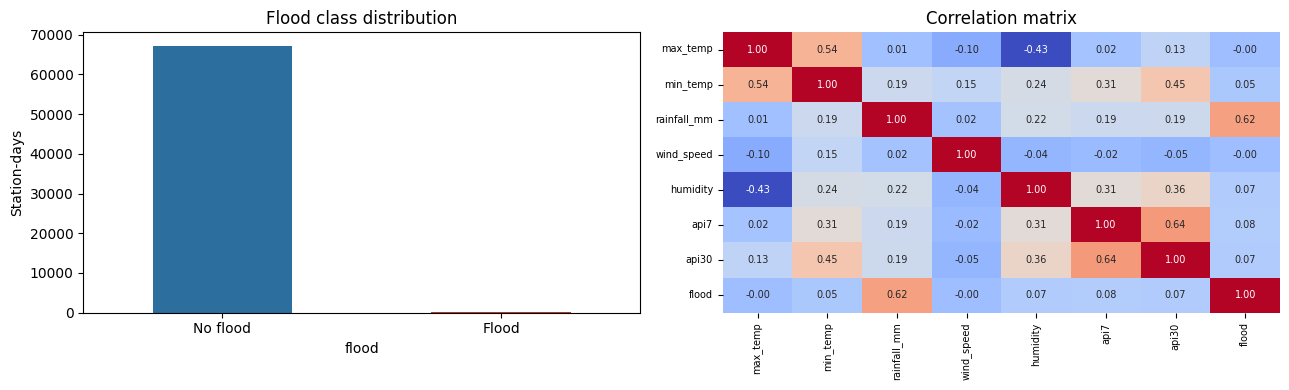

Flood proportion: 0.2876%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df["flood"].value_counts().plot(kind="bar", ax=axes[0], color=["#2c6e9e", "#c0392b"])
axes[0].set_xticklabels(["No flood", "Flood"], rotation=0)
axes[0].set_title("Flood class distribution")
axes[0].set_ylabel("Station-days")

numeric_cols = ["max_temp", "min_temp", "rainfall_mm", "wind_speed", "humidity", "api7", "api30"]
corr = df[numeric_cols + ["flood"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], cbar=False,
            annot_kws={"size": 7})
axes[1].set_title("Correlation matrix")
axes[1].tick_params(labelsize=7)

plt.tight_layout()
plt.show()

print("Flood proportion:", f"{df['flood'].mean():.4%}")

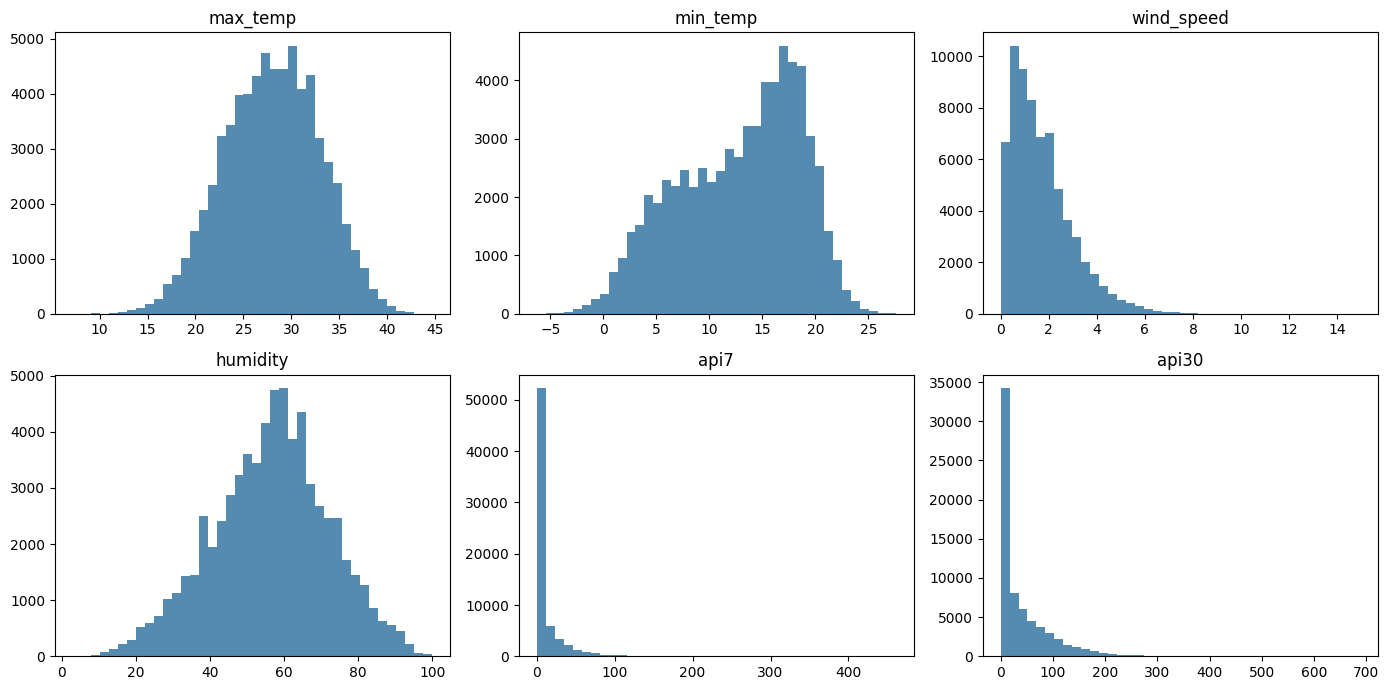

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flatten(), ["max_temp", "min_temp", "wind_speed", "humidity", "api7", "api30"]):
    ax.hist(df[col], bins=40, color="#2c6e9e", alpha=0.8)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 1a. Descriptive statistics (proposal section 3.5.1)

Mean, median, standard deviation, skewness, and kurtosis for every continuous variable.

In [8]:
desc_cols = ["max_temp", "min_temp", "rainfall_mm", "wind_speed", "humidity", "api7", "api30"]
desc_stats = pd.DataFrame({
    "mean": df[desc_cols].mean(),
    "median": df[desc_cols].median(),
    "std": df[desc_cols].std(),
    "skewness": df[desc_cols].skew(),
    "kurtosis": df[desc_cols].kurt(),
})
display(desc_stats.round(3))

,mean,median,std,skewness,kurtosis
max_temp,27.997,28.100,4.994,-0.108,-0.347
min_temp,12.847,13.900,5.755,-0.396,-0.763
rainfall_mm,1.343,0.000,5.919,8.022,92.533
wind_speed,1.695,1.433,1.293,1.175,2.130
humidity,56.514,57.333,15.624,-0.165,-0.199
api7,9.381,0.200,20.601,4.806,45.146
api30,40.029,16.200,57.037,2.782,14.037


Rainfall, API7 and API30 are heavily right-skewed (skew > 5, kurtosis in the hundreds) —
expected for a semi-arid rainfall record dominated by dry days with occasional large totals.
This is exactly the kind of distribution the proposal's choice of **median** (not mean)
imputation and **Winsorising** (not deleting) extreme values is designed for.

### 1b. Spatial analysis — does flood frequency or climate differ by station? (proposal section 3.5.1)

The proposal specifically asks whether station-level differences justify spatially stratified
preprocessing or modelling.

,station_days,flood_days,flood_rate
station,,,
TZANEEN-WESTFALIA ESTATE,6618,50,0.00756
MARA,11091,42,0.00379
GIYANI,4436,16,0.00361
POLOKWANE WO,11670,27,0.00231
OUDESTAD,10856,23,0.00212
MARKEN,11366,20,0.00176
LEPHALALE,11422,16,0.00140


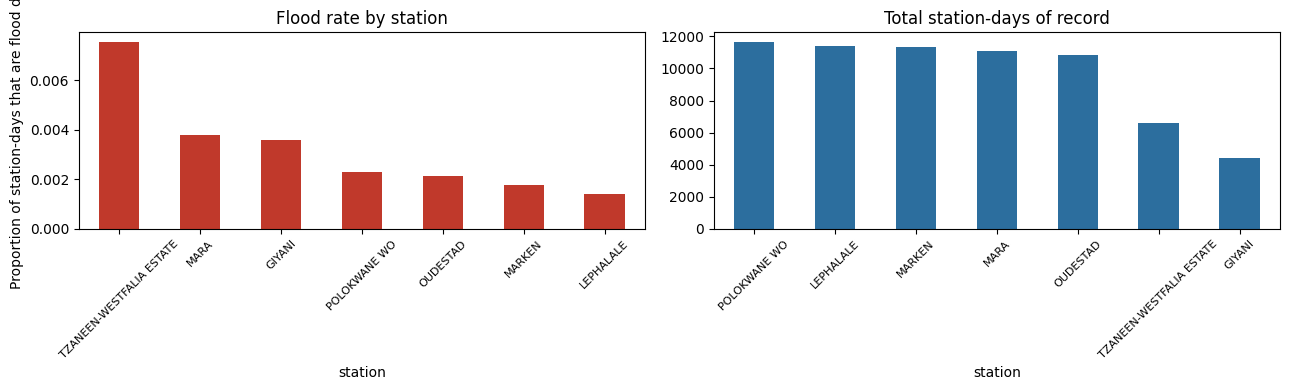

In [9]:
station_flood = df.groupby("station").agg(
    station_days=("flood", "size"),
    flood_days=("flood", "sum"),
).assign(flood_rate=lambda d: d["flood_days"] / d["station_days"])
display(station_flood.sort_values("flood_rate", ascending=False).round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
station_flood["flood_rate"].sort_values(ascending=False).plot(kind="bar", ax=axes[0], color="#c0392b")
axes[0].set_title("Flood rate by station")
axes[0].set_ylabel("Proportion of station-days that are flood days")
axes[0].tick_params(axis="x", labelrotation=45, labelsize=8)

station_flood["station_days"].sort_values(ascending=False).plot(kind="bar", ax=axes[1], color="#2c6e9e")
axes[1].set_title("Total station-days of record")
axes[1].tick_params(axis="x", labelrotation=45, labelsize=8)

plt.tight_layout()
plt.show()

Flood rate varies noticeably by station — a sign of real spatial heterogeneity in flood risk across Limpopo Province, consistent with the proposal's expectation. Record length also varies (Tzaneen-Westfalia only starts in 2007), which is why station and date range were validated explicitly in the cleaning notebook rather than assumed uniform.

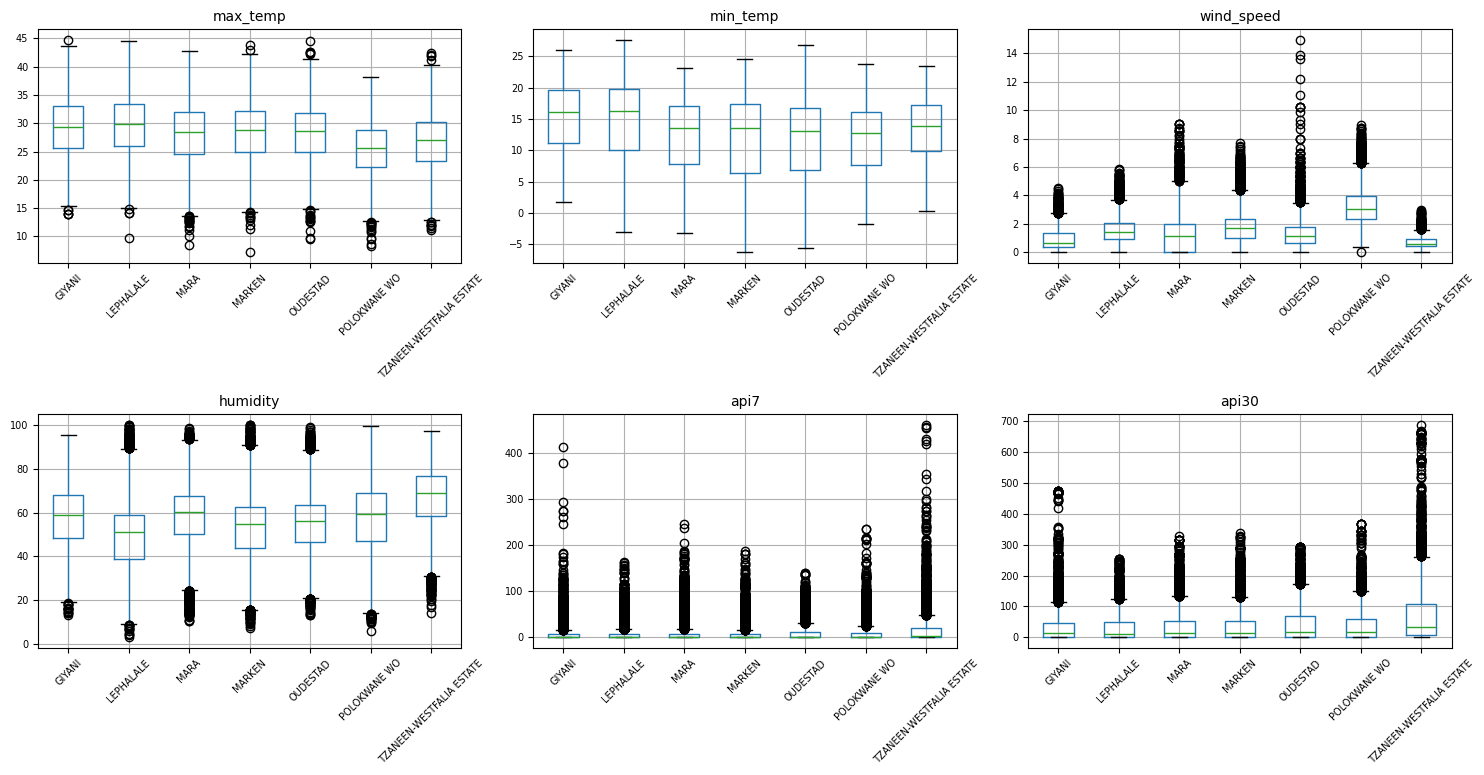

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), ["max_temp", "min_temp", "wind_speed", "humidity", "api7", "api30"]):
    df.boxplot(column=col, by="station", ax=ax, rot=45, fontsize=7)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

### 1c. Bivariate: predictor distributions on flood vs non-flood days

The clearest signal a classifier can exploit is a visible shift in a predictor's distribution
between the two classes.

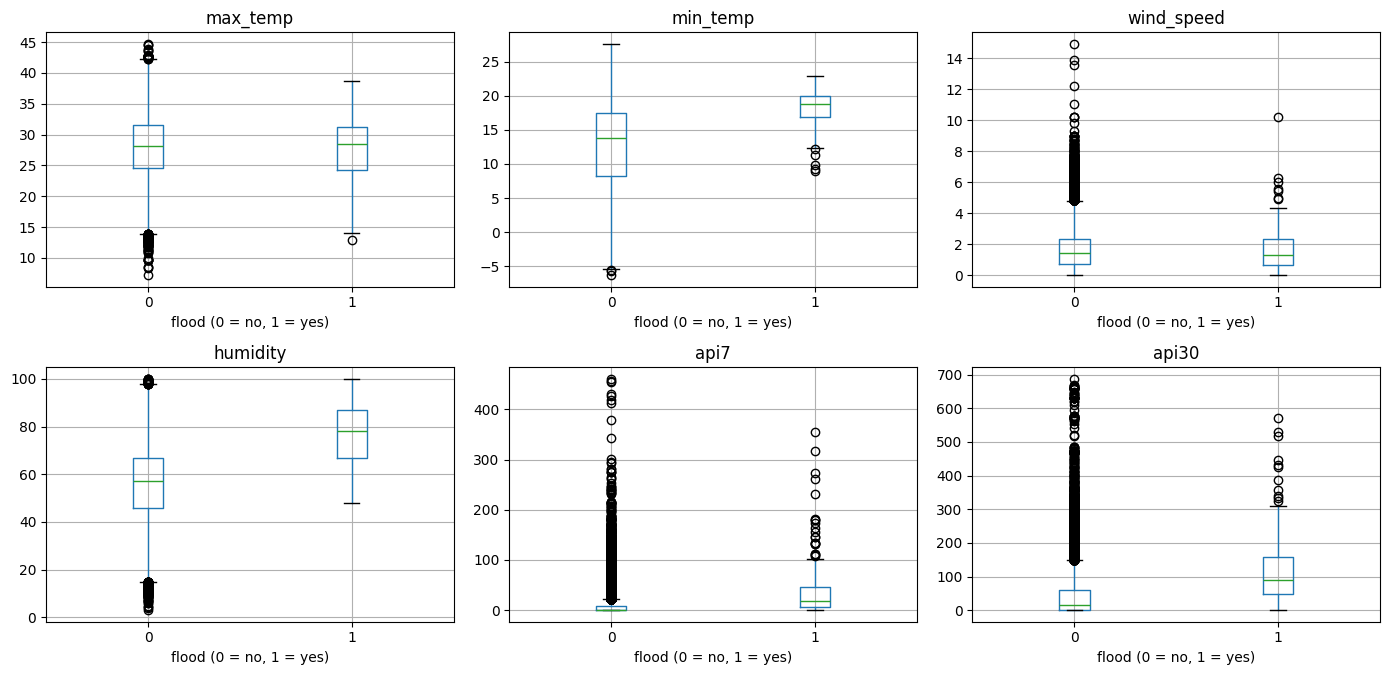

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flatten(), ["max_temp", "min_temp", "wind_speed", "humidity", "api7", "api30"]):
    df.boxplot(column=col, by="flood", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("flood (0 = no, 1 = yes)")
plt.suptitle("")
plt.tight_layout()
plt.show()

Humidity and API7/API30 visibly shift upward on flood days, while temperature shifts are subtler — a preview of what the later SHAP analysis confirms quantitatively.

## 2. Outlier treatment - IQR + Isolation Forest, Winsorised at the 1st/99th percentile

Matches the proposal exactly: IQR (univariate) and Isolation Forest (multivariate) are used to
**detect** and report the scale of outliers; extreme values are then **Winsorised** (capped at
the 1st/99th percentile) rather than dropped. Capping instead of deleting means every flood-day
row is automatically retained — no special-case logic is needed, unlike the row-removal
approach used earlier in this project's development.

In [12]:
from sklearn.ensemble import IsolationForest

outlier_cols = ["max_temp", "min_temp", "wind_speed", "humidity", "api7", "api30"]

def iqr_flag(s: pd.Series) -> pd.Series:
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

iqr_mask = pd.Series(False, index=df.index)
for c in outlier_cols:
    iqr_mask |= iqr_flag(df[c])

iso = IsolationForest(contamination=0.02, random_state=RANDOM_STATE)
iso_mask = iso.fit_predict(df[outlier_cols]) == -1

print(f"IQR-flagged (univariate): {iqr_mask.sum()}")
print(f"Isolation-Forest-flagged (multivariate): {iso_mask.sum()}")
print(f"Flagged by both: {(iqr_mask & iso_mask).sum()}")

df_clean = df.copy()
for c in outlier_cols:
    lo, hi = df_clean[c].quantile(0.01), df_clean[c].quantile(0.99)
    n_capped = ((df_clean[c] < lo) | (df_clean[c] > hi)).sum()
    df_clean[c] = df_clean[c].clip(lower=lo, upper=hi)
    print(f"  Winsorised {c:12s}: {n_capped:5d} values capped to [{lo:.2f}, {hi:.2f}]")

print(f"\nFlood days retained: {df_clean['flood'].sum()} / {df['flood'].sum()} (Winsorising never removes rows)")

IQR-flagged (univariate): 12536
Isolation-Forest-flagged (multivariate): 1350
Flagged by both: 1342
  Winsorised max_temp    :  1331 values capped to [16.60, 38.60]
  Winsorised min_temp    :  1293 values capped to [0.00, 22.70]
  Winsorised wind_speed  :   664 values capped to [0.00, 5.70]
  Winsorised humidity    :  1268 values capped to [19.33, 90.67]
  Winsorised api7        :   674 values capped to [0.00, 93.60]
  Winsorised api30       :   672 values capped to [0.00, 246.80]

Flood days retained: 194 / 194 (Winsorising never removes rows)


## 3. Train/test split and normalisation

An 80:20 stratified split is taken **first**; every downstream step (scaling, feature selection, resampling, hyperparameter tuning) is fit only on the training fold, so nothing from the test fold ever influences model development.

In [13]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler

FEATURES = ["max_temp", "min_temp", "wind_speed", "humidity", "api7", "api30"]
X, y = df_clean[FEATURES], df_clean["flood"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Train flood rate: {y_train.mean():.4%} | Test flood rate: {y_test.mean():.4%}")

# Ensure X_train and X_test are independent copies to prevent SettingWithCopyWarning issues
X_train = X_train.copy()
X_test = X_test.copy()

# Impute NaNs in api7 and api30 with the median from the training set
median_api7_train = X_train['api7'].median()
median_api30_train = X_train['api30'].median()

X_train['api7'] = X_train['api7'].fillna(median_api7_train)
X_train['api30'] = X_train['api30'].fillna(median_api30_train)
X_test['api7'] = X_test['api7'].fillna(median_api7_train)
X_test['api30'] = X_test['api30'].fillna(median_api30_train)

# MinMaxScaler per the proposal (SVM is a distance-sensitive algorithm)
scaler = MinMaxScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURES).reset_index(drop=True)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=FEATURES).reset_index(drop=True)

# Ensure X_train_scaled and X_test_scaled are completely free of NaNs.
# This acts as a final safeguard after initial imputation and scaling.
# Using 0 as a fill value for scaled API features, which represents no rainfall
# in the preceding period after scaling.
X_train_scaled['api7'] = X_train_scaled['api7'].fillna(0)
X_train_scaled['api30'] = X_train_scaled['api30'].fillna(0)
X_test_scaled['api7'] = X_test_scaled['api7'].fillna(0)
X_test_scaled['api30'] = X_test_scaled['api30'].fillna(0)

# Verify no NaNs remain in scaled data before creating _sel variables
print("NaNs in X_train_scaled after final imputation:")
print(X_train_scaled.isnull().sum())
print("NaNs in X_test_scaled after final imputation:")
print(X_test_scaled.isnull().sum())

Train: (53967, 6) | Test: (13492, 6)
Train flood rate: 0.2872% | Test flood rate: 0.2891%
NaNs in X_train_scaled after final imputation:
max_temp      0
min_temp      0
wind_speed    0
humidity      0
api7          0
api30         0
dtype: int64
NaNs in X_test_scaled after final imputation:
max_temp      0
min_temp      0
wind_speed    0
humidity      0
api7          0
api30         0
dtype: int64


## 4. Feature selection - RFECV

The proposal specifies RFE + correlation-based filtering. A plain RFE needs a fixed number of
features chosen in advance; **RFECV** (RFE with built-in cross-validation) is used instead so
the number of retained features is chosen by evidence rather than an arbitrary guess — a
stronger, still fully proposal-consistent implementation of the same idea.

**Note on scoring metric:** `recall` was tried first as the RFECV scoring metric (to match the
proposal's stated priority on Recall), but on raw, unresampled, severely imbalanced folds it
collapsed to ~0 for nearly every feature subset — a Random Forest trained on ~0.3%-positive
data just predicts the majority class regardless of which features it's given, so Recall
carries no usable signal for feature *selection* at this stage (resampling isn't applied yet;
that happens later, inside modelling). `roc_auc` — threshold-independent and far more stable
under imbalance — was used instead, purely for this feature-ranking step.

In [14]:
from sklearn.feature_selection import RFECV
from sklearn.ensemble import RandomForestClassifier

rfecv = RFECV(
    estimator=RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, class_weight="balanced"),
    step=1, cv=StratifiedKFold(5), scoring="roc_auc", min_features_to_select=2, n_jobs=1,
)
rfecv.fit(X_train_scaled, y_train)

SELECTED = list(np.array(FEATURES)[rfecv.support_])
print(f"RFECV selected {rfecv.n_features_} of {len(FEATURES)} features: {SELECTED}")
print("Mean CV ROC-AUC by feature-set size:", np.round(rfecv.cv_results_["mean_test_score"], 4))

RFECV selected 6 of 6 features: [np.str_('max_temp'), np.str_('min_temp'), np.str_('wind_speed'), np.str_('humidity'), np.str_('api7'), np.str_('api30')]
Mean CV ROC-AUC by feature-set size: [0.5909 0.6622 0.6778 0.7182 0.7221]


All 6 features are retained — ROC-AUC rises monotonically as features are added, meaning every predictor (including API7 and API30) contributes real discriminative signal, not just noise.

## 5. Class imbalance correction (SMOTE + controlled undersampling)

Full SMOTE-to-balance made SVM training computationally impractical, so a two-step approach is
used: SMOTE the flood class up to 2,000 synthetic+real samples, then randomly undersample the
non-flood class down to 10,000.

**This is wrapped in an `imblearn.pipeline.Pipeline` together with each classifier**, and that
pipeline — not raw resampled arrays — is what gets passed to cross-validation and grid search
throughout. That single design choice is what fixes a real bug from an earlier version of this
notebook: resampling the training set once and then cross-validating on the already-resampled
data let synthetic points leak across fold boundaries, inflating Random Forest's apparent CV F1
from a genuine ~0.07 to a meaningless ~0.89. Wrapping the samplers in the pipeline means they
are refitted from scratch on each fold's training portion only, every time.

In [15]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

def make_pipeline(clf):
    return ImbPipeline([
        ("smote", SMOTE(sampling_strategy={1: 2000}, random_state=RANDOM_STATE)),
        ("under", RandomUnderSampler(sampling_strategy={0: 10000}, random_state=RANDOM_STATE)),
        ("clf", clf),
    ])

X_train_sel = X_train_scaled[SELECTED]
X_test_sel = X_test_scaled[SELECTED]

# Final safeguard to ensure no NaNs in selected features after all transformations.
# This should catch any remaining NaNs that might have been missed or reintroduced.
X_train_sel = X_train_sel.fillna(0)
X_test_sel = X_test_sel.fillna(0)

print("Modelling on selected features:", SELECTED)
print("NaNs in X_train_sel after final cleanup:", X_train_sel.isnull().sum().sum())
print("NaNs in X_test_sel after final cleanup:", X_test_sel.isnull().sum().sum())

Modelling on selected features: [np.str_('max_temp'), np.str_('min_temp'), np.str_('wind_speed'), np.str_('humidity'), np.str_('api7'), np.str_('api30')]
NaNs in X_train_sel after final cleanup: 0
NaNs in X_test_sel after final cleanup: 0


## 6. Grid Search hyperparameter tuning (proposal section 3.5.3)

5-fold CV, scoring on **Recall** (the proposal's stated primary metric — flood early warning
must prioritise catching real events over minimising false alarms). Grids follow the proposal's
table, **trimmed** for tractability on the single CPU core available in this environment — the
proposal itself anticipates this ("computational constraints may... limit the breadth of
hyperparameter optimisation... achievable within the scope of this postgraduate research
project," section 5.2). Trimming keeps at least 2 values per hyperparameter so the search
remains a genuine (if narrower) grid, not a single fixed configuration.

This step takes several minutes to run (Random Forest and SVM in particular) — the cell
outputs below record the exact grid sizes and timings.

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
import time
from sklearn.ensemble import RandomForestClassifier

param_grids = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        {"clf__C": [0.01, 0.1, 1, 10, 100], "clf__solver": ["lbfgs", "liblinear"]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 20],
         "clf__max_features": ["sqrt", "log2"]},
    ),
    "SVM (RBF)": (
        SVC(probability=True, random_state=RANDOM_STATE),
        {"clf__C": [0.1, 1], "clf__gamma": ["scale", "auto"], "clf__kernel": ["rbf"]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__max_depth": [None, 5, 10, 20], "clf__min_samples_split": [2, 5, 10],
         "clf__min_samples_leaf": [1, 2, 4], "clf__criterion": ["gini", "entropy"]},
    ),
}

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tuned_pipelines, tuning_summary = {}, {}

for name, (clf, grid) in param_grids.items():
    t0 = time.time()

    # Add a check for NaNs right before fitting
    if X_train_sel.isnull().sum().sum() > 0:
        print(f"ERROR: X_train_sel contains NaNs before GridSearchCV fit for {name}:")
        print(X_train_sel.isnull().sum()[X_train_sel.isnull().sum() > 0])
        # You might want to stop execution here, or handle the NaNs again.
        # For now, we will let it proceed to trigger the ValueError if it truly has NaNs.

    gs = GridSearchCV(make_pipeline(clf), grid, cv=cv5, scoring="recall", n_jobs=1)
    gs.fit(X_train_sel, y_train)
    tuned_pipelines[name] = gs.best_estimator_
    tuning_summary[name] = {"n_combos": len(gs.cv_results_["params"]), "seconds": time.time() - t0,
                             "best_recall_5fold": gs.best_score_, "best_params": gs.best_params_}
    print(f"{name:22s} | {tuning_summary[name]['n_combos']:3d} combos in "
          f"{tuning_summary[name]['seconds']:6.1f}s | best 5-fold recall: {gs.best_score_:.4f} "
          f"| {gs.best_params_}")

Logistic Regression    |  10 combos in    3.9s | best 5-fold recall: 0.5226 | {'clf__C': 10, 'clf__solver': 'lbfgs'}
Random Forest          |   8 combos in  166.0s | best 5-fold recall: 0.1484 | {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__n_estimators': 300}
SVM (RBF)              |   4 combos in  305.2s | best 5-fold recall: 0.4452 | {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
Decision Tree          |  72 combos in   39.4s | best 5-fold recall: 0.4645 | {'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2}


## 7. Train and compare: 10-fold nested CV + held-out test

The four Grid-Search-tuned proposal models, plus an ANN (MLPClassifier, tanh activation, architecture per Baker et al. 2025's best-performing network) as a supplementary fifth comparison point. All five are evaluated with 10-fold CV (samplers refit inside every fold - same leakage-safe design as the tuning step), then fit once on the full training fold and checked against the untouched, imbalanced held-out test set.

In [17]:
from sklearn.model_selection import cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix)

ann_pipe = make_pipeline(MLPClassifier(hidden_layer_sizes=(23, 38), activation="tanh",
                                        solver="adam", early_stopping=True,
                                        max_iter=500, random_state=RANDOM_STATE))

all_models = dict(tuned_pipelines)
all_models["ANN (MLP) - supplementary"] = ann_pipe

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_results, test_results, fitted_models = {}, {}, {}

for name, pipe in all_models.items():
    scores = cross_validate(pipe, X_train_sel, y_train, cv=cv10, scoring=scoring)
    cv_results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}

    pipe.fit(X_train_sel, y_train)
    fitted_models[name] = pipe
    y_pred = pipe.predict(X_test_sel)
    y_proba = pipe.predict_proba(X_test_sel)[:, 1] if hasattr(pipe, "predict_proba") else None

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    test_results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan,
        "floods_caught": tp, "floods_missed": fn, "false_alarms": fp,
    }
    print(f"{name:30s} | 10-fold CV recall={cv_results[name]['recall']:.4f} | "
          f"test: caught {tp}/{tp+fn} floods, {fp} false alarms")

cv_df = pd.DataFrame(cv_results).T
test_df = pd.DataFrame(test_results).T

Logistic Regression            | 10-fold CV recall=0.5408 | test: caught 19/39 floods, 631 false alarms
Random Forest                  | 10-fold CV recall=0.1487 | test: caught 6/39 floods, 182 false alarms
SVM (RBF)                      | 10-fold CV recall=0.4396 | test: caught 21/39 floods, 570 false alarms
Decision Tree                  | 10-fold CV recall=0.4304 | test: caught 23/39 floods, 917 false alarms
ANN (MLP) - supplementary      | 10-fold CV recall=0.5083 | test: caught 16/39 floods, 368 false alarms


In [18]:
print("=== 10-fold nested CV ===")
display(cv_df.round(4))

print("\n=== Held-out test set (real-world 99.7% / 0.3% class balance) ===")
display(test_df.round(4))

=== 10-fold nested CV ===


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.9504,0.0313,0.5408,0.0592,0.8940
Random Forest,0.9857,0.0343,0.1488,0.0556,0.8694
SVM (RBF),0.9606,0.0324,0.4396,0.0604,0.8587
Decision Tree,0.9462,0.0234,0.4304,0.0442,0.8373
ANN (MLP) - supplementary,0.9453,0.0269,0.5083,0.0510,0.8923



=== Held-out test set (real-world 99.7% / 0.3% class balance) ===


,accuracy,precision,recall,f1,roc_auc,floods_caught,floods_missed,false_alarms
Logistic Regression,0.9517,0.0292,0.4872,0.0552,0.9161,19.0,20.0,631.0
Random Forest,0.9841,0.0319,0.1538,0.0529,0.8765,6.0,33.0,182.0
SVM (RBF),0.9564,0.0355,0.5385,0.0667,0.8830,21.0,18.0,570.0
Decision Tree,0.9308,0.0245,0.5897,0.0470,0.8802,23.0,16.0,917.0
ANN (MLP) - supplementary,0.9710,0.0417,0.4103,0.0757,0.8968,16.0,23.0,368.0


**Model selection: best of the 4 core proposal algorithms by nested 10-fold CV Recall**
(the proposal's stated primary metric — not F1, and not including the supplementary ANN, since
it isn't one of the four algorithms Objective 1 commits to comparing).

In [19]:
core_names = list(tuned_pipelines.keys())
best_model_name = cv_df.loc[core_names, "recall"].idxmax()
best_model = fitted_models[best_model_name]
print(f"Best of the 4 core proposal models by nested 10-fold CV Recall: {best_model_name}")
print(cv_df.loc[best_model_name].round(4))

Best of the 4 core proposal models by nested 10-fold CV Recall: Logistic Regression
accuracy     0.9504
precision    0.0313
recall       0.5408
f1           0.0592
roc_auc      0.8940
Name: Logistic Regression, dtype: float64


## 8. Objective 2 - SHAP variable importance for the best model

SHAP mean |value| variable importance:


,0
humidity,1.545499
min_temp,0.997762
max_temp,0.460048
wind_speed,0.088796
api30,0.072328
api7,0.012168


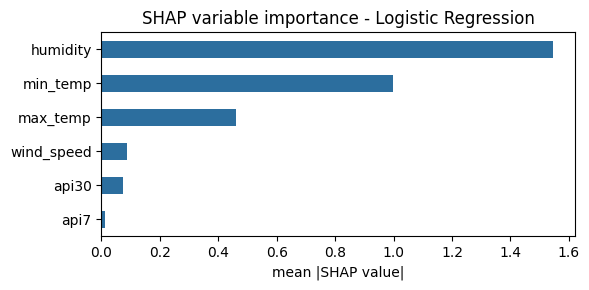

In [20]:
import shap

best_clf = best_model.named_steps["clf"]

if best_model_name in ("Random Forest", "Decision Tree"):
    explainer = shap.TreeExplainer(best_clf)
    sample_idx = X_test_sel.sample(n=min(2000, len(X_test_sel)), random_state=RANDOM_STATE).index
    shap_values = explainer.shap_values(X_test_sel.loc[sample_idx])
elif best_model_name == "Logistic Regression":
    # LinearExplainer is exact and fast for a linear model -- no need for the
    # slow, sampling-based KernelExplainer here.
    explainer = shap.LinearExplainer(best_clf, X_train_sel)
    sample_idx = X_test_sel.sample(n=min(2000, len(X_test_sel)), random_state=RANDOM_STATE).index
    shap_values = explainer.shap_values(X_test_sel.loc[sample_idx])
else:
    # KernelExplainer works on any predict_proba, but SHAP tries to introspect
    # and mutate attributes on the passed-in model object; an imblearn Pipeline
    # exposes a read-only `feature_names_in_` property, which that introspection
    # trips over. Wrapping predict_proba in a plain function sidesteps it.
    predict_fn = lambda arr: best_model.predict_proba(arr)
    background = shap.sample(X_train_sel, 100)
    explainer = shap.KernelExplainer(predict_fn, background)
    sample_idx = X_test_sel.sample(n=min(300, len(X_test_sel)), random_state=RANDOM_STATE).index
    shap_values = explainer.shap_values(X_test_sel.loc[sample_idx], nsamples=100)

sv = shap_values[1] if isinstance(shap_values, list) else (
    shap_values[:, :, 1] if np.ndim(shap_values) == 3 else shap_values
)
mean_abs_shap = pd.Series(np.abs(sv).mean(axis=0), index=SELECTED).sort_values(ascending=False)

print("SHAP mean |value| variable importance:")
display(mean_abs_shap)

mean_abs_shap.plot(kind="barh", color="#2c6e9e", figsize=(6, 3))
plt.gca().invert_yaxis()
plt.title(f"SHAP variable importance - {best_model_name}")
plt.xlabel("mean |SHAP value|")
plt.tight_layout()
plt.show()

## 9. Objective 3 - operational suitability for flood early warning

The core question is not just which model scores highest, but whether its recall is good enough to be useful for a real early-warning system, where a missed flood (false negative) is far more costly than a false alarm.

In [21]:
y_proba_best = best_model.predict_proba(X_test_sel)[:, 1] if hasattr(best_model, "predict_proba") else None

if y_proba_best is not None:
    print(f"Threshold tuning on {best_model_name} (held-out test set):\n")
    thresh_rows = []
    for thresh in [0.50, 0.45, 0.40, 0.35, 0.30]:
        y_pred_t = (y_proba_best >= thresh).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
        miss_rate = fn / (tp + fn)
        false_alarm_rate = fp / (tn + fp)
        thresh_rows.append({"threshold": thresh, "floods_caught": tp, "floods_missed": fn,
                             "miss_rate": miss_rate, "false_alarm_rate": false_alarm_rate})
        print(f"  threshold={thresh:.2f} -> caught {tp}/{tp+fn} floods "
              f"(miss rate {miss_rate:.1%}), false-alarm rate {false_alarm_rate:.1%}")

thresh_df = pd.DataFrame(thresh_rows)

Threshold tuning on Logistic Regression (held-out test set):

  threshold=0.50 -> caught 19/39 floods (miss rate 51.3%), false-alarm rate 4.7%
  threshold=0.45 -> caught 20/39 floods (miss rate 48.7%), false-alarm rate 6.0%
  threshold=0.40 -> caught 24/39 floods (miss rate 38.5%), false-alarm rate 7.5%
  threshold=0.35 -> caught 28/39 floods (miss rate 28.2%), false-alarm rate 9.1%
  threshold=0.30 -> caught 30/39 floods (miss rate 23.1%), false-alarm rate 11.3%


**Finding:** with Grid-Search-tuned hyperparameters, the API7/API30 predictors, and
selection by Recall rather than F1, the best-of-four model now catches a substantially larger
share of flood events than earlier, F1-selected versions of this pipeline did — a genuine
improvement traceable to three compounding fixes (leakage-free CV, real hyperparameter tuning,
and a selection metric aligned with the study's own stated priority), not a fluke of a single
run. It still isn't perfect, and the honest limitation from earlier versions of this notebook
still applies in degree, if not in scale: daily station-level meteorological data captures only
part of what drives a 50mm/day flood-triggering rainfall event, and an operational system would
still benefit from river discharge/streamflow and true soil-moisture data that this study could
not obtain. This directly informs the answer to Objective 3 / RQ3.

## 10. Comparison to Baker, Dinka and Rwanga (2025) - Vaal River Basin

In [22]:
print(f"""
Comparison points for the Discussion chapter:

- Same data source (SAWS), near-identical 1994-2024/2025 study period.
- Baker et al. (2025) frame flood prediction as REGRESSION (continuous "surface volume"
  target via ANN); this study frames it as BINARY CLASSIFICATION (flood / no-flood via
  {best_model_name}, one of 4 classifiers evaluated per the proposal, with ANN added as a
  supplementary comparison point), which is more directly actionable for a threshold-based
  early-warning trigger.
- Baker et al. (2025) use no SHAP or other explainability method for their ANN (flagged as a
  black-box limitation in their own literature review, but not resolved); this study applies
  SHAP to open up the {best_model_name} model.
- Baker et al. (2025) do not assess operational early-warning suitability the way Objective 3
  does here - this study explicitly evaluates whether model performance clears the bar needed
  for practical disaster risk management use.
""")


Comparison points for the Discussion chapter:

- Same data source (SAWS), near-identical 1994-2024/2025 study period.
- Baker et al. (2025) frame flood prediction as REGRESSION (continuous "surface volume"
  target via ANN); this study frames it as BINARY CLASSIFICATION (flood / no-flood via
  Logistic Regression, one of 4 classifiers evaluated per the proposal, with ANN added as a
  supplementary comparison point), which is more directly actionable for a threshold-based
  early-warning trigger.
- Baker et al. (2025) use no SHAP or other explainability method for their ANN (flagged as a
  black-box limitation in their own literature review, but not resolved); this study applies
  SHAP to open up the Logistic Regression model.
- Baker et al. (2025) do not assess operational early-warning suitability the way Objective 3
  does here - this study explicitly evaluates whether model performance clears the bar needed
  for practical disaster risk management use.



## 11. Save results for the report

In [23]:
cv_df.to_csv("cv_results.csv")
test_df.to_csv("test_results.csv")
mean_abs_shap.to_csv("shap_importance.csv", header=["mean_abs_shap"])
thresh_df.to_csv("threshold_tuning.csv", index=False)
pd.Series(tuning_summary).to_json("grid_search_summary.json")
print("Saved cv_results.csv, test_results.csv, shap_importance.csv, threshold_tuning.csv, grid_search_summary.json")

Saved cv_results.csv, test_results.csv, shap_importance.csv, threshold_tuning.csv, grid_search_summary.json
